In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load hexagons with toilet counts
hex_grid = gpd.read_file(
    "../data/processed/sydney_hex_grid.geojson"
)

# Load 2021 SA1 population and boundaries
population = pd.read_csv(
    "../data/processed/sa1_population_2021.csv",
    dtype={"sa1_code": str}
)

sa1_boundaries = gpd.read_file(
    "../data/raw/abs_sa1_2021/SA1_2021_AUST_GDA2020.shp"
)

sa1_boundaries["SA1_CODE21"] = (
    sa1_boundaries["SA1_CODE21"].astype(str)
)

sa1 = sa1_boundaries.merge(
    population,
    left_on="SA1_CODE21",
    right_on="sa1_code",
    how="left",
    validate="one_to_one"
)

# Use a projected coordinate system for area calculations
hex_grid = hex_grid.to_crs("EPSG:7856")
sa1 = sa1.to_crs("EPSG:7856")

print("Hexagons:", len(hex_grid))
print("SA1 areas:", len(sa1))

Hexagons: 16228
SA1 areas: 61845


In [2]:
# Keep SA1s that intersect at least one hexagon
sa1 = gpd.sjoin(
    sa1,
    hex_grid[["geometry"]].union_all()
    if False else gpd.GeoDataFrame(
        geometry=[hex_grid.geometry.union_all()],
        crs=hex_grid.crs
    ),
    how="inner",
    predicate="intersects"
).drop(columns="index_right")

print("Relevant SA1 areas:", len(sa1))

Relevant SA1 areas: 10728


In [3]:
# Keep only necessary columns
sa1 = sa1[
    ["SA1_CODE21", "population", "geometry"]
].copy()

hexes = hex_grid[
    ["hex_id", "geometry"]
].copy()

# Calculate original SA1 area BEFORE intersecting
sa1["sa1_area_m2"] = sa1.geometry.area

# Find the intersection between every SA1 and hexagon
overlaps = gpd.overlay(
    hexes,
    sa1,
    how="intersection",
    keep_geom_type=True
)

print("Number of intersections:", len(overlaps))

Number of intersections: 55532


In [4]:
overlaps["overlap_area_m2"] = overlaps.geometry.area

overlaps["population_contribution"] = (
    overlaps["population"]
    * overlaps["overlap_area_m2"]
    / overlaps["sa1_area_m2"]
)

# Sum all SA1 contributions for each hexagon
hex_population = (
    overlaps.groupby("hex_id")["population_contribution"]
    .sum(min_count=1)
    .reset_index(name="population_est")
)

display(hex_population.head())

,hex_id,population_est
0,89be08184dbffff,16.524263
1,89be081a00bffff,51.389710
2,89be081a01bffff,61.526032
3,89be081a043ffff,61.693961
4,89be081a047ffff,53.332429


In [5]:
hex_grid = hex_grid.merge(
    hex_population,
    on="hex_id",
    how="left",
    validate="one_to_one"
)

# Missing overlap means zero estimated population
hex_grid["population_est"] = (
    hex_grid["population_est"].fillna(0)
)

# Calculate population density per hexagon
hex_grid["area_km2"] = hex_grid.geometry.area / 1_000_000

hex_grid["population_density"] = (
    hex_grid["population_est"] / hex_grid["area_km2"]
)

print("Total hexagons:", len(hex_grid))
print("Estimated population:", round(hex_grid["population_est"].sum()))
print("Hexagons with population:", (hex_grid["population_est"] > 0).sum())

display(hex_grid[
    ["hex_id", "toilet_count", "population_est", "population_density"]
].head())

Total hexagons: 16228
Estimated population: 4491614
Hexagons with population: 16006


,hex_id,toilet_count,population_est,population_density
0,89be081a427ffff,0,2.573064,20.323744
1,89be081b483ffff,0,290.758144,2296.466691
2,89be081a053ffff,0,61.694254,487.304332
3,89be08c5b13ffff,0,339.654950,2682.672676
4,89be081b5bbffff,0,1.847987,14.596371


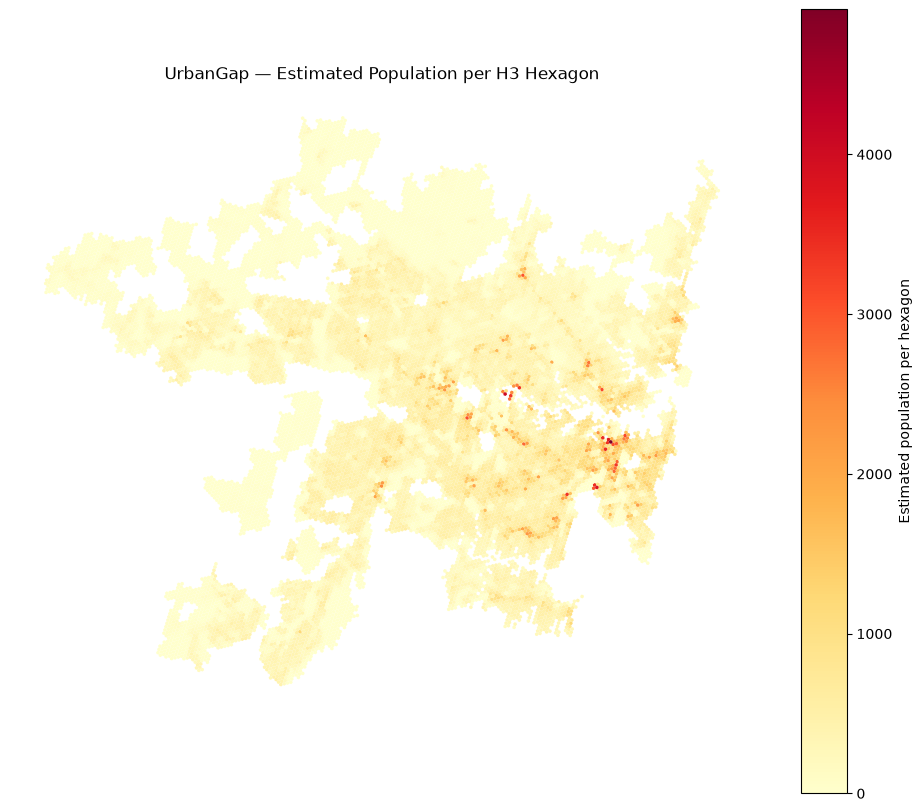

In [6]:
fig, ax = plt.subplots(figsize=(12, 12))

hex_grid.plot(
    column="population_est",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    linewidth=0,
    legend_kwds={"label": "Estimated population per hexagon"}
)

ax.set_title("UrbanGap — Estimated Population per H3 Hexagon")
ax.set_axis_off()

plt.show()

In [7]:
hex_grid.to_file(
    "../data/processed/sydney_hex_features.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_features.csv",
    index=False
)